# Customer Churn Prediction

**Business question:** which customers are likely to cancel, so the company can act to retain them?

**Dataset:** Telco Customer Churn (Kaggle, by blastchar), 7,043 customers, 21 columns.


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, precision_recall_curve)

pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

## 1. Load and clean

In [2]:
try:
    df = pd.read_csv('Telco-Customer-Churn.csv')
except UnicodeDecodeError:
    # the file is really an Excel workbook with a .csv name
    df = pd.read_excel('Telco-Customer-Churn.csv', engine='openpyxl')
    df.to_csv('Telco-Customer-Churn.csv', index=False)   # overwrite with a real CSV

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# TotalCharges is text with blanks for brand-new customers (tenure = 0). Their total really is 0.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df = df.drop(columns=['customerID'])          # identifier, not a feature
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print('Churn rate:', df['Churn'].mean().round(3))

Churn rate: 0.265


## 2. Quick EDA

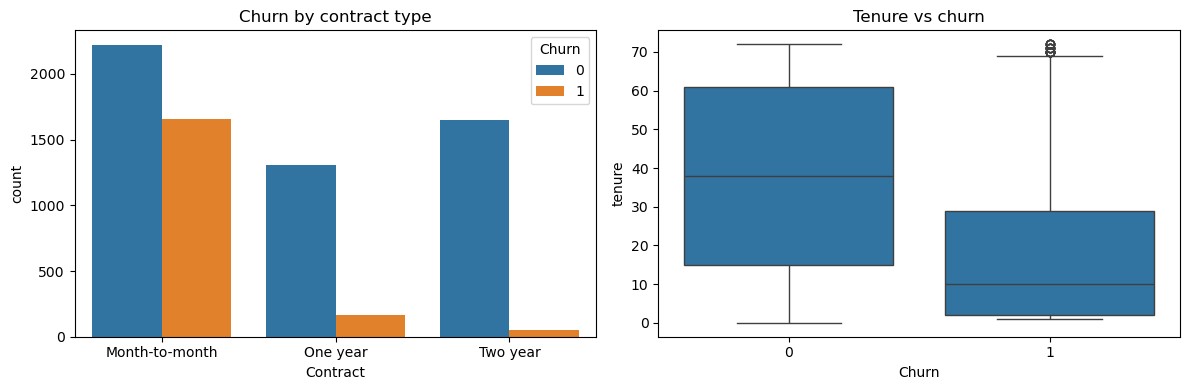

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[0])
axes[0].set_title('Churn by contract type')
sns.boxplot(data=df, x='Churn', y='tenure', ax=axes[1])
axes[1].set_title('Tenure vs churn')
plt.tight_layout()
plt.show()

## 3. Split and build the preprocessing + model pipelines

In [5]:
X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_cols = [c for c in X.columns if c not in numeric_cols]   # includes SeniorCitizen (0/1)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
])

log_reg = Pipeline([
    ('prep', preprocess),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced')),
])

rf = Pipeline([
    ('prep', preprocess),
    ('model', RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                     class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)),
])

log_reg.fit(X_train, y_train)
rf.fit(X_train, y_train)

,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## 4. Evaluate both models

Focus on the **Churn** row: recall (share of real churners caught) and precision (share of flagged customers who really churn).

In [6]:
for name, model in [('Logistic Regression', log_reg), ('Random Forest', rf)]:
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]
    print(f'=== {name} ===')
    print(classification_report(y_test, preds, target_names=['No Churn', 'Churn']))
    print('ROC AUC:', round(roc_auc_score(y_test, probs), 3), '\n')

=== Logistic Regression ===
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC AUC: 0.842 

=== Random Forest ===
              precision    recall  f1-score   support

    No Churn       0.90      0.78      0.83      1035
       Churn       0.55      0.75      0.64       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409

ROC AUC: 0.842 



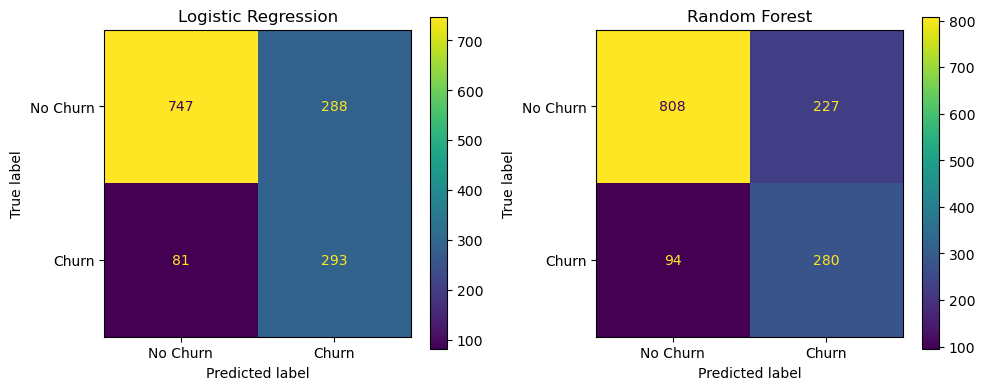

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, [('Logistic Regression', log_reg), ('Random Forest', rf)]):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax,
                                          display_labels=['No Churn', 'Churn'])
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 5. Choose a decision threshold (without peeking at the test set)

The default cut-off is 0.5, but the business may want a different balance between catching churners and false alarms.
We pick the threshold that maximises F1 for churn using **cross-validated predictions on the training data only**,
then check it once on the test set.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_probs = cross_val_predict(log_reg, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof_probs)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best_threshold = float(thr[np.argmax(f1)])
print('Chosen threshold:', round(best_threshold, 3))

test_probs = log_reg.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= best_threshold).astype(int)
print(classification_report(y_test, test_preds, target_names=['No Churn', 'Churn']))

Chosen threshold: 0.576
              precision    recall  f1-score   support

    No Churn       0.89      0.78      0.83      1035
       Churn       0.54      0.72      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



## 6. What drives churn? (logistic regression coefficients)

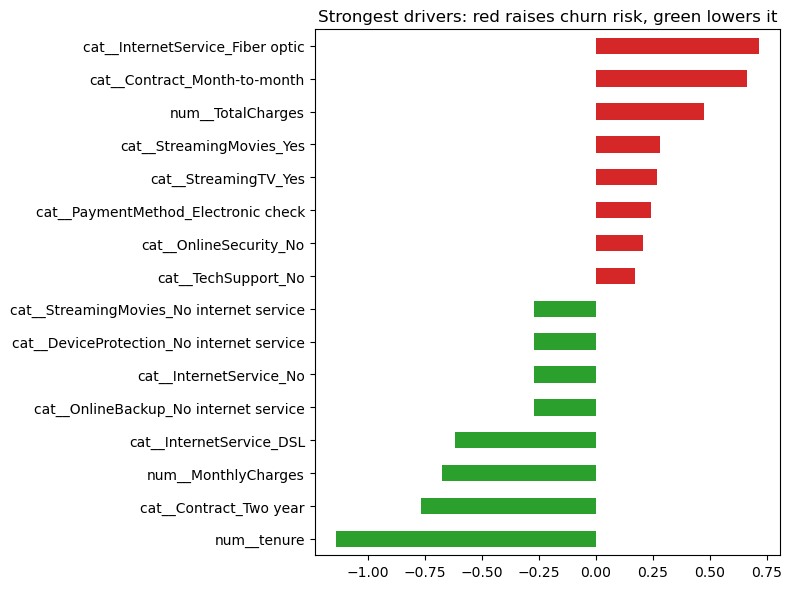

In [9]:
feature_names = log_reg.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(log_reg.named_steps['model'].coef_[0], index=feature_names).sort_values()

top = pd.concat([coefs.head(8), coefs.tail(8)])
top.plot(kind='barh', figsize=(8, 6), color=['tab:green' if v < 0 else 'tab:red' for v in top])
plt.title('Strongest drivers: red raises churn risk, green lowers it')
plt.tight_layout()
plt.show()

## 7. Save one pipeline file plus a small config

`churn_pipeline.joblib` takes a raw customer row (a DataFrame with the original column names) and returns probabilities.
`churn_config.json` holds the threshold, column lists and valid dropdown values, which the API and Streamlit app will reuse.

In [10]:
final_model = log_reg    # chosen on churn recall + ROC AUC; change here if you decide otherwise

joblib.dump(final_model, 'churn_pipeline.joblib')

config = {
    'model': 'LogisticRegression (balanced) in a Pipeline',
    'threshold': best_threshold,
    'numeric_cols': numeric_cols,
    'categorical_cols': categorical_cols,
    'feature_order': list(X.columns),
    'categories': {c: sorted(X[c].astype(str).unique().tolist()) for c in categorical_cols},
    'sklearn_version': sklearn.__version__,
}
with open('churn_config.json', 'w') as f:
    json.dump(config, f, indent=2)

print('Saved churn_pipeline.joblib and churn_config.json')

Saved churn_pipeline.joblib and churn_config.json


## 8. Sanity check: reload and predict one raw customer

In [11]:
loaded = joblib.load('churn_pipeline.joblib')

sample = pd.DataFrame([{
    'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No', 'tenure': 3,
    'PhoneService': 'Yes', 'MultipleLines': 'No', 'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No', 'OnlineBackup': 'No', 'DeviceProtection': 'No', 'TechSupport': 'No',
    'StreamingTV': 'Yes', 'StreamingMovies': 'Yes', 'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes', 'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 95.5, 'TotalCharges': 286.5,
}])[config['feature_order']]

p = loaded.predict_proba(sample)[0, 1]
print(f'Churn probability: {p:.2f} -> {"HIGH RISK" if p >= config["threshold"] else "low risk"}')

Churn probability: 0.89 -> HIGH RISK
